# Lab 10: Spatial Comparisons with SWOT and PACE

In the previous labs, we have explored ways to generate maps and time series for a variety of different satellite data-derived products. In each of these cases, we were just using a single data product. We often would like to intercompare different products as the same locations. However, most data products will not be co-located in space because the satellites have different orbits, the sensors have different resolutions, and/or the products were simply generated on different grids.

In this lab we will see an example analyzing two different Level 2 products at the same location - one from NASA's Plankton, Aerosol, Cloud, ocean Ecosystem (PACE) satellite and one from NASA's Surface Water and Ocean Topography (SWOT) satellite.

This notebook has four parts:
1. Find and download PACE and SWOT data
2. Plot data side-by-side
3. Detrend SWOT data to remove a "roll" error
4. Interpolate data onto a common spatial grid

**Import the modules for this notebook**

To begin, let's import the modules used for this notebook

In [1]:
# import the packages used in previous notebooks
import os
import numpy as np
import matplotlib.pyplot as plt
import netCDF4 as nc4
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# import a package for solving a system of equations
from scipy.linalg import lstsq

# import a package for interpolation
from scipy.interpolate import griddata

## Motivation

A submesoscale front is a strong gradient between waters with different temperature, salinity and/or densities in the ocean. Fronts are sites of counter-balance upwelling and downwelling flows that can extend several hundred meters down into the water column. Like other upwelling mechanisms, the upwelling limb of circulation near a front can often be associated with productivity. This effect is due to the vertical fluxes of nutrients from depth into the photic zone where nutrients may limit growth. Fronts are typically visible in sea surface height data because they are associated with the edges of eddies and other rotating features.

In this lab, we're going to compare two metrics that relate phytoplankton biomass to the presence of submesoscale fronts. For phytoplankton, we'll examine chlorophyll-a estimates from the ocean color instrument on NASA's PACE satellite. For fronts, we'll examine sea surface height anomalies from NASA's SWOT satellite.

## Part 1: Finding PACE and SWOT Granules

In the past few labs, we've used automated Python scripts to obtain satellite data. However, sometimes we'd like to search for a given scene that fits our need. NASA's [Earthdata](https://search.earthdata.nasa.gov/) portal provides a convenient way to search for scenes of interest. In this lab, we'll use this tool to search for two different scenes that encompasses the California Current region around Monterey Bay area during the spring upwelling season.

Before we begin, let's define a data folder where we will store our data:

In [2]:
data_folder = '../data/labs/lab10'

### Download a PACE Granule

When searching on the Earthdata portal, it's helpful to know what data product you're looking for - there's lots of different products available! For PACE, we will search for the level 2 data product, described on the [PACE OCI Level 2 product](https://www.earthdata.nasa.gov/data/catalog/ob-cloud-pace-oci-l2-bgc-3.2) landing page. These pages and descriptions are useful for understanding the temporal and spatial coverage of the data product, and they provide a product identifier for finding the product in Earthdata. As we can see on the PACE data page indicated above, the identifier for this data set is **PACE_OCI_L2_BGC**. Enter this identifier into the search tab of the Earthdata page.

Next, add in spatial and temporal queries to narrow down the dataset. For this lab, we'll investigate the time frame 4/16/26 to 4/19/26 and a spatial extent around the California Current region. You can add the spatial query by adding a rectangle or polygon to the map on Earth data.

After implementing these queries, your search should look like the following screenshot:

```{figure} ../images/labs/lab10/pace_granule_selection.png
---
height: 400px
name: pace-query
---
Screenshot of a data request from NASA's Earthdata portal for a PACE Level 2 granule.
```

To follow along with this lab, find and download the following granule: 
**PACE_OCI.20260417T201750.L2.OC_BGC.V3_2.nc**.

Be sure to put this into your Lab 10 data directory.

### Download a SWOT Granule

Similar to the PACE data search, we'll also use the same strategy to find a SWOT granule. The SWOT product we will use for this lab is the [SWOT Level 2 Basic](https://www.earthdata.nasa.gov/data/catalog/pocloud-swot-l2-lr-ssh-basic-d-d) product. As we can see on the landing page, the identifier for this product is **SWOT_L2_LR_SSH_BASIC_D**.

For this lab, we will use the following SWOT granule: 
**SWOT_L2_LR_SSH_Basic_049_011_20260418T021204_20260418T030251_PID0_01.nc**.

Be sure to store this in your Lab 10 directory. Note that the measurements in this file were taken approximately 6 hours later than the measurements from PACE.

## Part 2: Plotting PACE and SWOT for Comparison

### Plotting PACE Data

Now that we've got our data in hand, let's plot it on a map and have a look. First, read in the data from the netCDF file:

In [3]:
ds = nc4.Dataset(os.path.join(data_folder,
                              'PACE_OCI.20260417T201750.L2.OC_BGC.V3_2.nc'))
pace_lon = ds.groups['navigation_data'].variables['longitude'][:,:]
pace_lat = ds.groups['navigation_data'].variables['latitude'][:,:]
pace_chl = ds.groups['geophysical_data'].variables['chlor_a'][:,:]
ds.close()

Next, let's add the data to a map using `cartopy`:

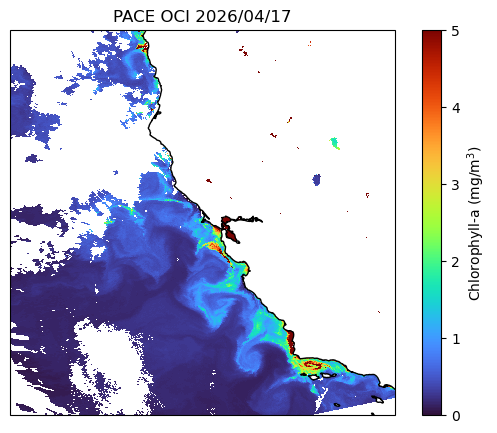

In [4]:
fig = plt.figure(figsize=(7,5))
proj = ccrs.PlateCarree()
ax1 = fig.add_subplot(projection=proj)
C = ax1.pcolormesh(pace_lon, pace_lat, pace_chl, vmin=0, vmax=5,
               cmap='turbo',transform=ccrs.PlateCarree())
plt.colorbar(C, label='Chlorophyll-a (mg/m$^3$)')
plt.title('PACE OCI 2026/04/17')
ax1.coastlines(color='k')
ax1.set_extent([-128,-118, 33,43], ccrs.PlateCarree())
plt.show()

It looks like there's lots of interesting submesoscale features we can see reflected in the chlorophyll-a estimates.

### Plotting SWOT Data
Next, let's plot the data from the SWOT granule. As before, let's read this in from the netCDF file:

In [5]:
# read in the  file info
file_name = 'SWOT_L2_LR_SSH_Basic_049_011_20260418T021204_20260418T030251_PID0_01.nc'
ds = nc4.Dataset(os.path.join(data_folder,file_name))
swot_lon = ds.variables['longitude'][:,:]
swot_lat = ds.variables['latitude'][:,:]
swot_ssha = ds.variables['ssha_karin_2'][:,:]
ssha_qual = ds.variables['ssha_karin_2_qual'][:,:]
ds.close()

# nan out bad values
swot_ssha[ssha_qual!=0] = np.nan
swot_ssha[swot_ssha>5] = np.nan
swot_lon[swot_lon>180] -= 360

Let's see what this data looks like:

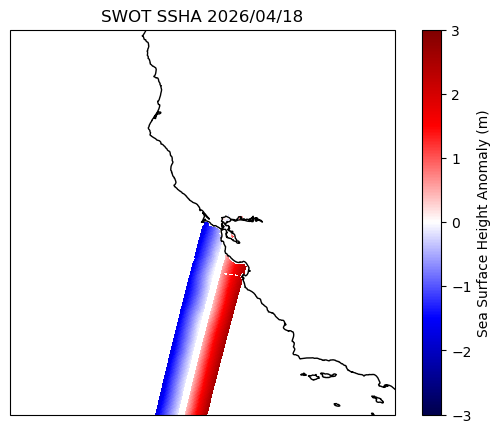

In [6]:
fig = plt.figure(figsize=(7,5))
proj = ccrs.PlateCarree()
ax1 = fig.add_subplot(projection=proj)
C = ax1.pcolormesh(swot_lon, swot_lat, swot_ssha, vmin=-3, vmax=3,
               cmap='seismic',transform=ccrs.PlateCarree())
plt.colorbar(C, label='Sea Surface Height Anomaly (m)')
plt.title('SWOT SSHA 2026/04/18')
ax1.coastlines(color='k')
ax1.set_extent([-128,-118, 33,43], ccrs.PlateCarree())
plt.show()

As we can see, there is a significant "ramp" in the SWOT data resulting from the processing of KaRIn measurements and spacecraft orientation to retrieve sea surface height anomalies. Since the process by which this ramp is removed can impact the interpretation of oceanographic properties, the science team has opted to leave this anomaly in the data released publicly, tasking scientists to address this issue in their own processing. In the next section, we'll see one approach to remove this ramp and recover spatial variations in sea surface height anomaly.

## Part 3: Detrending SWOT Data
In the previous section, we saw that there is a cross-track "ramp" in the data. To remove this ramp and to reveal spatial patterns in sea surface height anomalies, we'll make the assumption that the errors vary consistently in both the along-track and cross-track directions. We'll approximate these errors using a quadratic polynomial fit to the data.

Specifically, we are going to compute a polynomial of the form

$$
p(x,y) = C_0 + C_1x + C_2y +C_3x^2 + C_4y^2
$$

where $x$ and $y$ correspond to the columns and rows of the data grid and the $C_i$ coefficients will be derived from the data. 

To understand how the polynomial will be constructed, let's take a look at how the dataset is organized by plotting the latitude field of the data product as a function of the rows and columns of the data structure:

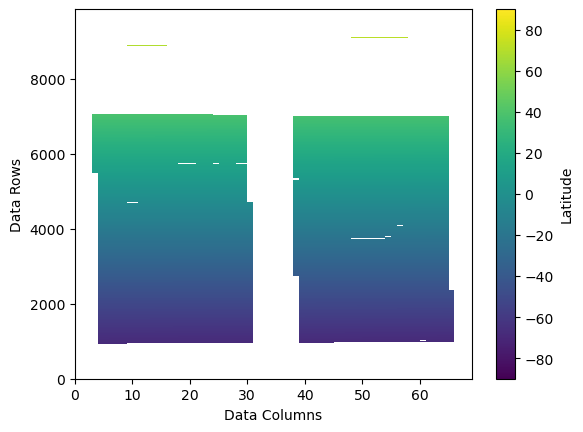

In [7]:
swot_lat_masked = np.ma.masked_where(~np.isfinite(swot_ssha), swot_lat)
C = plt.pcolormesh(swot_lat_masked, vmin=-90, vmax=90)
plt.ylabel('Data Rows')
plt.xlabel('Data Columns')
plt.colorbar(C, label='Latitude')
plt.show()

As we can see, the granule follows the swath along the track and it stretches from the south pole to the north pole (the whole ascending track!). Since we are going to fit a polynomial to the data to remove errors, let's subset our data to the region only around the California Current where our investigation is focused.

### Subsetting to a Region of Interest
To subset our SWOT data, let's compute the rows containing the data in our domain:

In [8]:
# compute the rows in the region of interest
rows, _ = np.where(np.logical_and(swot_lat>=33, swot_lat<=43))

# subset the data to the rows around the CA current
swot_lon_CA = swot_lon[np.min(rows):np.max(rows), :]
swot_lat_CA = swot_lat[np.min(rows):np.max(rows), :]
swot_ssha_CA = swot_ssha[np.min(rows):np.max(rows), :]

### Computing a Detrended Polynomial

Next, we'll fit a polynomial to the data subset. To compute this polynomial, we will find the coefficients $C_i$ as a function of the columns $x$ and rows $y$ of the data grid. 

To solve for these coefficients, we want to find the $C_i$'s such that the difference between the data and the polynomial is minimized - a classic least square errors problem.

If we write this as a system of equations for each of the $N$ data points

$$
\begin{align*}
 H(x_1, y_1) &= C_0 + C_1x + C_2y +C_3x^2 + C_4y^2 + \varepsilon_1\\
 &\vdots\\
 H(x_N, y_N) &= C_0 + C_1x + C_2y +C_3x^2 + C_4y^2 + \varepsilon_N\\
\end{align*}
$$

we aim to minimize the errors $\varepsilon_n$. This can be written in matrix form as 

$$
\begin{align*}
\begin{bmatrix}H(x_1, y_1) \\ \vdots \\  H(x_N, y_N) \end{bmatrix} &= \begin{bmatrix}1 & x_1 & y_1 & x_1^2 & y_1^2 \\ &&\vdots \\ 1 & x_N & y_N & x_N^2 & y_N^2 \end{bmatrix} \begin{bmatrix}C_0 \\ C_1 \\ C_2 \\ C_3 \\ C_4 \end{bmatrix}
\end{align*}
$$

We can write this more concisely as
$$
\begin{align*}
\textbf{H} &= \textbf{A}\textbf{C}
\end{align*}
$$

Clearly, this is an undetermined system because the number of data points $N$ is much larger than the five coefficients $C_i$. However, the solution to the system which minimizes the errors computed with the root mean square error is the "psuedo inverse"

$$
\begin{align*}
\textbf{C} &= (\textbf{A}^T\textbf{A})^{-1}\textbf{A}^T\textbf{H}
\end{align*}
$$

This can be computed manually, but its also conveniently provided in the `lstsq` function of `scipy`'s `linalg` module. Let's code this up

In [9]:
# compute X and Y (columns and rows)
cols_CA = np.arange(np.shape(swot_lon_CA)[1],)
rows_CA = np.arange(np.shape(swot_lon_CA)[0],)
X, Y = np.meshgrid(cols_CA, rows_CA)

# formulate the design matrix (A)
x = np.ravel(X)
y = np.ravel(Y)
A = np.column_stack([np.ones(x.shape[0]), x, y, x**2, y**2])

# fomulate the target matrix (H)
H = swot_ssha_CA.ravel()

# identify where the points are real
non_nan_indices = ~np.isnan(H)

# mask the points to real values 
A = A[non_nan_indices,:]
H = H[non_nan_indices]

# compute the coefficients in C matrix using scipy 
C, _, _, _ = lstsq(A, H)

With the coefficients in hand, we can now compute the polynomial

In [10]:
polynomial = C[0] + C[1]*X + C[2]*Y + C[3]*X**2 + C[4]*Y**2 

Let's have a look at what this polynomial looks like:

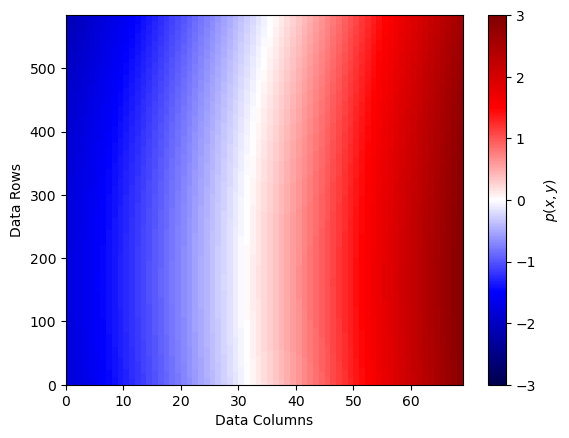

In [11]:
plt.pcolormesh(polynomial, cmap='seismic', vmin=-3, vmax=3)
plt.colorbar(label='$p(x,y)$')
plt.ylabel('Data Rows')
plt.xlabel('Data Columns')
plt.show()

As we can see, we've estimated the cross-track ramp in the data although we also see some along-track variation.

Next, we remove this ramp from our data product:

In [12]:
swot_ssha_CA_detrended = swot_ssha_CA - polynomial

Let's see how our new detrended data looks:

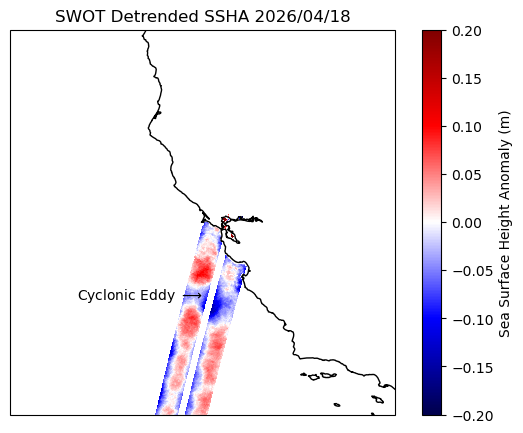

In [13]:
fig = plt.figure(figsize=(7,5))
proj = ccrs.PlateCarree()
ax1 = fig.add_subplot(projection=proj)
C = ax1.pcolormesh(swot_lon_CA, swot_lat_CA, swot_ssha_CA_detrended,
                   vmin=-0.2, vmax=0.2,
                   cmap='seismic',transform=ccrs.PlateCarree())
plt.colorbar(C, label='Sea Surface Height Anomaly (m)')
plt.title('SWOT Detrended SSHA 2026/04/18')
plt.text(-123, 36, 'Cyclonic Eddy $\\longrightarrow$', ha='right')
ax1.coastlines(color='k')
ax1.set_extent([-128,-118, 33,43], ccrs.PlateCarree())
plt.show()

As we can see, the removal of the "ramp" reveals spatial variations in sea surface height that were not detectable in our previous view of the data. Namely, we can see an area of anomalously low sea surface height which could be associated with a cyclonic (counter-clockwise) eddy.

Let's compare this new view of our sea surface height data with the chlorophyll-a estimates to see if we can find any potential connections:

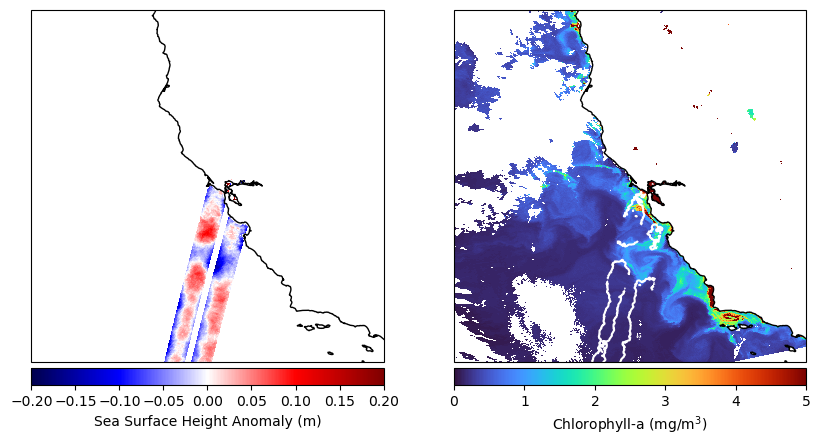

In [14]:
fig = plt.figure(figsize=(10,7))
proj = ccrs.PlateCarree()

# plot the SWOT data
ax1 = fig.add_subplot(1, 2, 1, projection=proj)
C = plt.pcolormesh(swot_lon_CA, swot_lat_CA, swot_ssha_CA_detrended,
                   vmin=-0.2, vmax=0.2, cmap='seismic', transform=ccrs.PlateCarree())
plt.colorbar(C, orientation='horizontal',
            label = 'Sea Surface Height Anomaly (m)', pad=0.01)
ax1.coastlines(color='k')
ax1.set_extent([-128,-118, 33,43], ccrs.PlateCarree())

# plot the PACE data
ax2 = fig.add_subplot(1, 2, 2, projection=proj)
C = ax2.pcolormesh(pace_lon, pace_lat, pace_chl,
                   vmin=0, vmax=5, cmap='turbo',transform=ccrs.PlateCarree())
plt.colorbar(C, orientation='horizontal',
            label='Chlorophyll-a (mg/m$^3$)', pad=0.01)
ax2.contour(swot_lon_CA, swot_lat_CA, swot_ssha_CA_detrended,
                   levels = [0], transform=ccrs.PlateCarree(), colors='w')
ax2.coastlines(color='k')
ax2.set_extent([-128,-118, 33,43], ccrs.PlateCarree())
plt.show()

On the right hand plot, we can see that the location of the cyclonic eddy is consistent with a similar feature in the chlorophyll-a estimates! This is made particularly clear by overlaying the zero-SSHA contours on the chlorophyll-a data.

## Part 4: Interpolating Onto A Common Grid

In this section, we are going to consider a comparison of the sea surface height anomaly and chlorophyll-a across the cyclonic eddy identified above. However, this comparison is made a little tricky due to the fact that the data are provided on very different grids. Here, we'll see how to interpolate one data set onto the same grid as another.

### A Cross-Eddy Transect
To begin, we'll identify a cross-eddy transect in the SWOT data. Since the orbit of the satellite is directly across the eddy, we can take this directly from the SWOT data using a column in the data grid:

In [15]:
# choose a sample column
sample_column = 45

# sample the data on the sample column
subset_ssha = swot_ssha_CA_detrended[:, sample_column]
subset_lon = swot_lon_CA[:, sample_column]
subset_lat = swot_lat_CA[:, sample_column]

# limit transect offshore
offshore_latitudes = np.logical_and(subset_lat>=33, subset_lat<=37)
subset_ssha = subset_ssha[offshore_latitudes]
subset_lon = subset_lon[offshore_latitudes]
subset_lat = subset_lat[offshore_latitudes]

Let's see what this transect looks like:

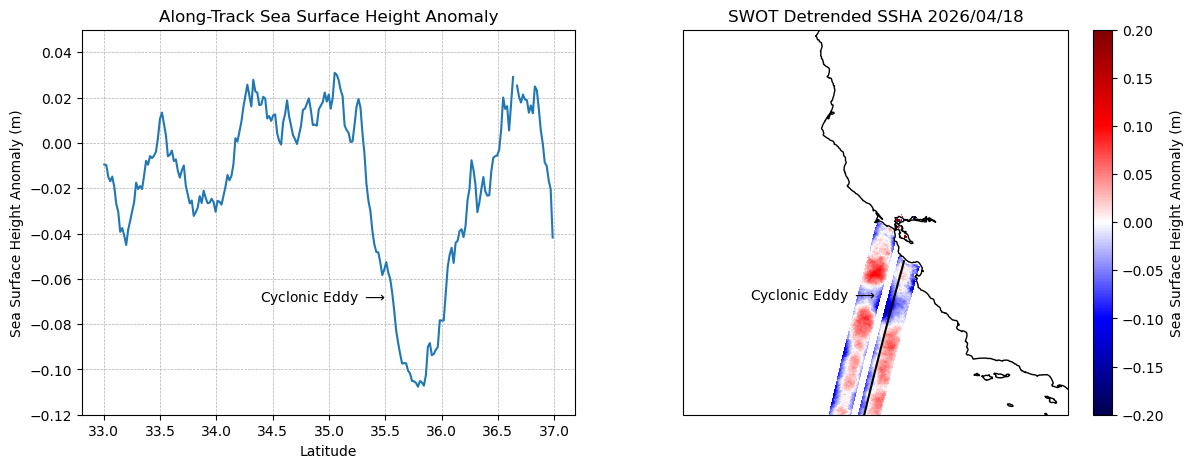

In [16]:
fig = plt.figure(figsize=(14,5))

ax1 = fig.add_subplot(1, 2, 1)
plt.plot(subset_lat, subset_ssha)
plt.text(35.5, -0.07, 'Cyclonic Eddy $\\longrightarrow$', ha='right')
plt.ylim(-0.12,0.05)
plt.grid(linestyle='--', linewidth=0.5)
plt.ylabel('Sea Surface Height Anomaly (m)')
plt.xlabel('Latitude')
plt.title('Along-Track Sea Surface Height Anomaly')

proj = ccrs.PlateCarree()
ax1 = fig.add_subplot(1, 2, 2, projection=proj)
C = ax1.pcolormesh(swot_lon_CA, swot_lat_CA, swot_ssha_CA_detrended,
                   vmin=-0.2, vmax=0.2,
                   cmap='seismic',transform=ccrs.PlateCarree())
ax1.plot(subset_lon, subset_lat, 'k-', transform=ccrs.PlateCarree())
plt.colorbar(C, label='Sea Surface Height Anomaly (m)')
plt.title('SWOT Detrended SSHA 2026/04/18')
plt.text(-123, 36, 'Cyclonic Eddy $\\longrightarrow$', ha='right')
ax1.coastlines(color='k')
ax1.set_extent([-128,-118, 33,43], ccrs.PlateCarree())

plt.show()

### Interpolating PACE Data Onto the Transect
Next, we'll interpolate the PACE data onto the SSHA transect using a linear interpolation. This is made quite easy with the help of `scipy`'s `interpolate` module:

In [17]:
# identify the pace points and values
pace_points = np.column_stack([pace_lon.ravel(), pace_lat.ravel()])
pace_values = pace_chl.ravel()

# remove nonsense values from the PACE data
non_nan_indices = np.logical_and(pace_values>=0, pace_values<=100)
pace_points = pace_points[non_nan_indices, :]
pace_values = pace_values[non_nan_indices]

# interpolate the data with the griddata function
subset_pace = griddata(pace_points, pace_values, (subset_lon, subset_lat))

Let's see how the data compare:

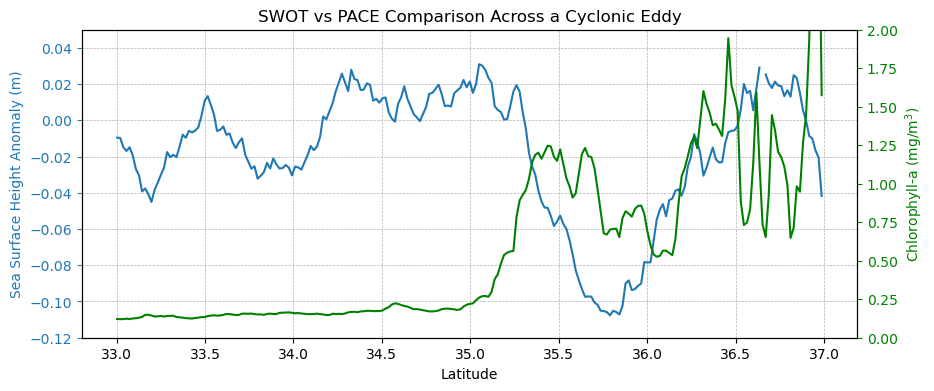

In [18]:
plt.figure(figsize=(10,4))

# plot the SSHA data on the left axis
plt.plot(subset_lat, subset_ssha)
plt.ylim(-0.12,0.05)
plt.grid(linestyle='--', linewidth=0.5)
plt.xlabel('Latitude')
plt.ylabel('Sea Surface Height Anomaly (m)', color="tab:blue")
plt.gca().tick_params(axis="y", color="tab:blue", labelcolor="tab:blue")
plt.title('SWOT vs PACE Comparison Across a Cyclonic Eddy')

ax2 = plt.gca().twinx()
ax2.plot(subset_lat, subset_pace,'g-')
ax2.set_ylim([0,2])
ax2.tick_params(axis="y", color="g", labelcolor="g")
ax2.set_ylabel('Chlorophyll-a (mg/m$^3$)', color='g')
plt.show()

As we can see, there is a sharp gradient in chlorophyll at the edge of the cyclonic eddy! This comparison reflects how physical oceanographic processes are reflected in biological processes and can be generalized to lots of other processes and regions. 

### &#129300; Try it for yourself!

Using this same approach, examine another system in the ocean to investigate a relationship between sea surface height and another oceanographic variable. You can investigate chlorophyll-a or you can use any of the variables explored in previous labs.